In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import os

In [3]:
%pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
df = pd.read_excel("../data/Online Retail.xlsx")

In [7]:
df.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [9]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [11]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [14]:
df["CustomerID"].isnull().sum()

np.int64(135080)

In [15]:
df.describe(include='O')


,InvoiceNo,StockCode,Description,Country
count,541909,541909,540455,541909
unique,25900,4070,4223,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1114,2313,2369,495478


In [18]:
df[df["CustomerID"].isnull()].head(15)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1447,536544,21790,VINTAGE SNAP CARDS,9,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1448,536544,21791,VINTAGE HEADS AND TAILS CARD GAME,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1449,536544,21801,CHRISTMAS TREE DECORATION WITH BELL,10,2010-12-01 14:32:00,0.43,NaN,United Kingdom
1450,536544,21802,CHRISTMAS TREE HEART DECORATION,9,2010-12-01 14:32:00,0.43,NaN,United Kingdom
1451,536544,21803,CHRISTMAS TREE STAR DECORATION,11,2010-12-01 14:32:00,0.43,NaN,United Kingdom


In [19]:
df[df["Quantity"]<0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [20]:
df[df["Quantity"]<0 & df["CustomerID"].isnull()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [22]:
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

In [24]:
df[df["InvoiceNo"].str.match("^\\d{6}$") == False]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315.0,United Kingdom


In [25]:
df["InvoiceNo"].str.replace("[0-9]","",regex=True).unique()

array(['', 'C', 'A'], dtype=object)

In [27]:
df[df["InvoiceNo"].str.startswith("A") == True]


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [31]:
df[df["InvoiceNo"].str.startswith("C") == True]


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315.0,United Kingdom


In [34]:
df[df["InvoiceNo"].str.match("^\\d{6}$")  | df["InvoiceNo"].str.match("^C\\d{6}") ]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [35]:
df[~df["InvoiceNo"].str.match("^\\d{6}$")  | ~df["InvoiceNo"].str.match("^C\\d{6}") ]


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [39]:
df["CustomerID"].isnull().sum()

np.int64(135080)

In [41]:
customer_ids = df["CustomerID"].dropna().astype(int).astype(str)

invalid_customerids = customer_ids[~customer_ids.str.match("^\\d{5}$")]

invalid_customerids.unique()

array([], dtype=object)

In [42]:
df["StockCode"].isnull().sum()

np.int64(0)

In [44]:
stock_codes = df["StockCode"].dropna().astype(str)

invalid_stock_codes = stock_codes[~stock_codes.str.match("^\\d{5}$")]

invalid_stock_codes.unique()

array(['85123A', '84406B', '84029G', ..., '85179a', '90214U', '47591b'],
      shape=(1124,), dtype=object)

In [45]:
invalid_stock_codes.nunique()

1124

In [46]:
invalid_stock_codes.value_counts().head(20)

StockCode
85123A    2313
85099B    2159
POST      1256
85099C     960
82494L     943
85099F     842
DOT        710
M          571
84970S     546
84596B     541
84997D     481
84029G     474
15056N     467
84970L     460
84596F     452
84029E     452
47591D     446
85049E     423
47590B     402
47590A     394
Name: count, dtype: int64

In [47]:
df[(df["StockCode"].str.match("^\\d{5}$")==False) & (df["StockCode"].str.match("^\\d{5}[a-zA-Z]+$")==False)]["StockCode"].unique()

array(['POST', 'D', 'C2', 'DOT', 'M', 'BANK CHARGES', 'S', 'AMAZONFEE',
       'DCGS0076', 'DCGS0003', 'gift_0001_40', 'DCGS0070', 'm',
       'gift_0001_50', 'gift_0001_30', 'gift_0001_20', 'DCGS0055',
       'DCGS0072', 'DCGS0074', 'DCGS0069', 'DCGS0057', 'DCGSSBOY',
       'DCGSSGIRL', 'gift_0001_10', 'PADS', 'DCGS0004', 'DCGS0073',
       'DCGS0071', 'DCGS0068', 'DCGS0067', 'DCGS0066P', 'B', 'CRUK'],
      dtype=object)

In [48]:
df[
    df["StockCode"].isin(
        ["85123A", "85099B", "POST", "DOT", "M"]
    )
][
    ["StockCode", "Description", "Quantity", "UnitPrice"]
].head(30)

,StockCode,Description,Quantity,UnitPrice
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55
45,POST,POSTAGE,3,18.00
49,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55
66,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55
177,85099B,JUMBO BAG RED RETROSPOT,100,1.65
220,85123A,WHITE HANGING HEART T-LIGHT HOLDER,64,2.55
234,85099B,JUMBO BAG RED RETROSPOT,100,1.65
262,85123A,WHITE HANGING HEART T-LIGHT HOLDER,32,2.55
278,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55
364,85123A,WHITE HANGING HEART T-LIGHT HOLDER,4,2.95


In [49]:
invalid_stock_rows = df[
    df["StockCode"].isin(invalid_stock_codes.unique())
]

stockcode_summary = (
    invalid_stock_rows
    .groupby("StockCode")
    .agg(
        RowCount=("StockCode", "size"),
        DescriptionCount=("Description", "nunique"),
        ExampleDescription=("Description", "first")
    )
    .sort_values("RowCount", ascending=False)
)

stockcode_summary.head(30)

,RowCount,DescriptionCount,ExampleDescription
StockCode,,,
85123A,2313,4,WHITE HANGING HEART T-LIGHT HOLDER
85099B,2159,1,JUMBO BAG RED RETROSPOT
POST,1256,1,POSTAGE
85099C,960,1,JUMBO BAG BAROQUE BLACK WHITE
82494L,943,3,WOODEN FRAME ANTIQUE WHITE
85099F,842,1,JUMBO BAG STRAWBERRY
DOT,710,1,DOTCOM POSTAGE
M,571,1,Manual
84970S,546,1,HANGING HEART ZINC T-LIGHT HOLDER


In [50]:
df[
    df["StockCode"].isin(
        ["85123A", "85099B", "POST", "DOT", "M"]
    )
].groupby("StockCode").agg(
    TotalRows=("StockCode", "size"),
    MissingCustomerID=(
        "CustomerID",
        lambda x: x.isna().sum()
    ),
    KnownCustomerID=(
        "CustomerID",
        lambda x: x.notna().sum()
    )
)

,TotalRows,MissingCustomerID,KnownCustomerID
StockCode,,,
85099B,2159,497,1662
85123A,2313,236,2077
DOT,710,694,16
M,571,106,465
POST,1256,60,1196


In [51]:
nonstandard_stock = ~df["StockCode"].astype(str).str.fullmatch(
    r"\d{5}", na=False
)

comparison = pd.crosstab(
    nonstandard_stock,
    df["CustomerID"].isna(),
    normalize="index"
) * 100

comparison

CustomerID,False,True
StockCode,,
False,76.179174,23.820826
True,65.257959,34.742041


In [53]:
pd.crosstab(
    df["InvoiceNo"].str.startswith("C",na= False),
    df["Quantity"]<0,
    margins =True
)

Quantity,False,True,All
InvoiceNo,,,
False,531285,1336,532621
True,0,9288,9288
All,531285,10624,541909


In [54]:
negative_without_c = df[
    (df["Quantity"] < 0) &
    (~df["InvoiceNo"].str.startswith("C", na=False))
]

negative_without_c["Description"].value_counts().head(20)

Description
check                         120
damages                        45
damaged                        42
?                              41
sold as set on dotcom          20
Damaged                        14
thrown away                     9
Unsaleable, destroyed.          9
??                              7
damages?                        5
ebay                            5
wet damaged                     5
smashed                         4
CHECK                           3
missing                         3
wet pallet                      3
Dotcom sales                    2
reverse 21/5/10 adjustment      2
mixed up                        2
incorrect stock entry.          2
Name: count, dtype: int64

In [55]:
negative_without_c[
    negative_without_c["Description"].str.contains(
        r"damag|thrown away|unsaleable|destroyed|adjustment|incorrect stock entry",
        case=False,
        na=False
    )
][
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "UnitPrice",
        "CustomerID",
        "Country"
    ]
].head(30)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
13264,537432,35833G,damages,-43,2010-12-06 16:10:00,0.0,NaN,United Kingdom
42564,540010,22501,reverse 21/5/10 adjustment,-100,2011-01-04 11:13:00,0.0,NaN,United Kingdom
42566,540012,22502,reverse 21/5/10 adjustment,-100,2011-01-04 11:14:00,0.0,NaN,United Kingdom
50849,540564,22617,"mouldy, thrown away.",-2600,2011-01-10 10:36:00,0.0,NaN,United Kingdom
51049,540638,72038P,damages,-990,2011-01-10 12:14:00,0.0,NaN,United Kingdom
73589,542361,85161,samples/damages,-20,2011-01-27 12:47:00,0.0,NaN,United Kingdom
82794,543257,84611B,thrown away,-1430,2011-02-04 16:06:00,0.0,NaN,United Kingdom
82796,543259,84612B,thrown away,-162,2011-02-04 16:07:00,0.0,NaN,United Kingdom
82797,543260,84613A,thrown away,-230,2011-02-04 16:07:00,0.0,NaN,United Kingdom
82799,543262,84614A,thrown away,-390,2011-02-04 16:08:00,0.0,NaN,United Kingdom


In [56]:
negative_without_c["CustomerID"].value_counts(dropna=False)

CustomerID
NaN    1336
Name: count, dtype: int64

In [58]:
negative_without_c[
    (negative_without_c["UnitPrice"] == 0) &
    (negative_without_c["CustomerID"].isnull())
].shape

(1336, 8)

In [59]:
negative_without_c[
    (negative_without_c["UnitPrice"] == 0) &
    (negative_without_c["CustomerID"].isnull())
]["Description"].value_counts().head(20)

Description
check                         120
damages                        45
damaged                        42
?                              41
sold as set on dotcom          20
Damaged                        14
thrown away                     9
Unsaleable, destroyed.          9
??                              7
damages?                        5
ebay                            5
wet damaged                     5
smashed                         4
CHECK                           3
missing                         3
wet pallet                      3
Dotcom sales                    2
reverse 21/5/10 adjustment      2
mixed up                        2
incorrect stock entry.          2
Name: count, dtype: int64

In [60]:
pd.Series({
    "Total rows": len(negative_without_c),
    "Zero UnitPrice": (
        negative_without_c["UnitPrice"] == 0
    ).sum(),
    "Missing CustomerID": (
        negative_without_c["CustomerID"].isna()
    ).sum(),
    "Both zero price and missing CustomerID": (
        (negative_without_c["UnitPrice"] == 0) &
        (negative_without_c["CustomerID"].isna())
    ).sum()
})

Total rows                                1336
Zero UnitPrice                            1336
Missing CustomerID                        1336
Both zero price and missing CustomerID    1336
dtype: int64

In [61]:
pd.Series({
    "Total rows": len(df),
    "Zero UnitPrice": (df["UnitPrice"] == 0).sum(),
    "Positive Quantity and Zero UnitPrice": (
        (df["Quantity"] > 0) &
        (df["UnitPrice"] == 0)
    ).sum(),
    "Negative Quantity and Zero UnitPrice": (
        (df["Quantity"] < 0) &
        (df["UnitPrice"] == 0)
    ).sum()
})

Total rows                              541909
Zero UnitPrice                            2515
Positive Quantity and Zero UnitPrice      1179
Negative Quantity and Zero UnitPrice      1336
dtype: int64

In [62]:
zero_price_positive = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] == 0)
]

zero_price_positive[
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "UnitPrice",
        "CustomerID",
        "Country"
    ]
].head(30)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
4348,536765,84952C,NaN,19,2010-12-02 14:43:00,0.0,NaN,United Kingdom


In [63]:
df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] == 0)
][
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "UnitPrice",
        "CustomerID",
        "Country"
    ]
].head(30)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
4348,536765,84952C,NaN,19,2010-12-02 14:43:00,0.0,NaN,United Kingdom


In [64]:
pd.Series({
    "Total rows": len(zero_price_positive),
    "Missing Description": (
        zero_price_positive["Description"].isna().sum()
    ),
    "Missing CustomerID": (
        zero_price_positive["CustomerID"].isna().sum()
    ),
    "Known CustomerID": (
        zero_price_positive["CustomerID"].notna().sum()
    )
})

Total rows             1179
Missing Description     592
Missing CustomerID     1139
Known CustomerID         40
dtype: int64

In [65]:
pd.crosstab(
    zero_price_positive["Description"].isna(),
    zero_price_positive["CustomerID"].isna(),
    margins=True
)

CustomerID,False,True,All
Description,,,
False,40,547,587
True,0,592,592
All,40,1139,1179


In [66]:
zero_price_positive[
    zero_price_positive["CustomerID"].notna()
][
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "UnitPrice",
        "CustomerID",
        "Country"
    ]
]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.0,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.0,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,2011-01-13 15:10:00,0.0,15107.0,United Kingdom
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2011-02-10 13:08:00,0.0,17560.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,2011-03-23 10:25:00,0.0,13239.0,United Kingdom
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,2011-03-30 12:45:00,0.0,13113.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,2011-04-04 14:42:00,0.0,14410.0,United Kingdom


In [67]:
df[df["InvoiceNo"] == "578841"]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.0,13256.0,United Kingdom


In [68]:
zero_price_positive[
    zero_price_positive["CustomerID"].notna()
].groupby("InvoiceNo").agg(
    LineCount=("InvoiceNo", "size"),
    TotalQuantity=("Quantity", "sum"),
    Descriptions=("Description", "nunique"),
    CustomerID=("CustomerID", "first")
).sort_values("TotalQuantity", ascending=False).head(10)

,LineCount,TotalQuantity,Descriptions,CustomerID
InvoiceNo,,,,
578841,1,12540,1,13256.0
564651,4,576,4,14646.0
562973,1,240,1,14911.0
574138,1,216,1,12415.0
554037,1,80,1,12415.0
540372,2,48,2,13081.0
575579,2,44,2,13081.0
547417,1,36,1,13239.0
543599,1,16,1,17560.0


In [69]:
df[df["InvoiceNo"] == "564651"]


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
314745,564651,23270,SET OF 2 CERAMIC PAINTED HEARTS,96,2011-08-26 14:19:00,0.0,14646.0,Netherlands
314746,564651,23268,SET OF 2 CERAMIC CHRISTMAS REINDEER,192,2011-08-26 14:19:00,0.0,14646.0,Netherlands
314747,564651,22955,36 FOIL STAR CAKE CASES,144,2011-08-26 14:19:00,0.0,14646.0,Netherlands
314748,564651,21786,POLKADOT RAIN HAT,144,2011-08-26 14:19:00,0.0,14646.0,Netherlands


In [70]:
df[
    (df["CustomerID"] == 14646) &
    (df["InvoiceNo"] != "564651")
][
    ["InvoiceNo", "InvoiceDate", "Description", "Quantity", "UnitPrice"]
].head(20)

,InvoiceNo,InvoiceDate,Description,Quantity,UnitPrice
37952,539491,2010-12-20 10:09:00,PACK OF 12 WOODLAND TISSUES,12,0.29
37953,539491,2010-12-20 10:09:00,PACK OF 12 PINK POLKADOT TISSUES,12,0.29
37954,539491,2010-12-20 10:09:00,SET OF 3 CAKE TINS PANTRY DESIGN,2,4.95
37955,539491,2010-12-20 10:09:00,JUMBO STORAGE BAG SUKI,1,1.95
37956,539491,2010-12-20 10:09:00,PACK OF 20 SPACEBOY NAPKINS,2,0.85
37957,539491,2010-12-20 10:09:00,FUNKY WASHING UP GLOVES ASSORTED,1,2.10
37958,539491,2010-12-20 10:09:00,RED RETROSPOT BIG BOWL,2,4.95
37959,539491,2010-12-20 10:09:00,JAM MAKING SET WITH JARS,1,4.25
37960,539491,2010-12-20 10:09:00,CHARLOTTE BAG SUKI DESIGN,2,0.85
37961,539491,2010-12-20 10:09:00,SET/10 IVORY POLKADOT PARTY CANDLES,2,1.25


In [71]:
df_customer = df.dropna(subset=["CustomerID"]).copy()

In [72]:
df_customer

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [74]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [75]:
df_customer.describe()


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,406829.000000,406829,406829.000000,406829.000000
mean,12.061303,2011-07-10 16:30:57.879207424,3.460471,15287.690570
min,-80995.000000,2010-12-01 08:26:00,0.000000,12346.000000
25%,2.000000,2011-04-06 15:02:00,1.250000,13953.000000
50%,5.000000,2011-07-31 11:48:00,1.950000,15152.000000
75%,12.000000,2011-10-20 13:06:00,3.750000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,248.693370,NaN,69.315162,1713.600303


In [76]:
print("Original shape:", df.shape)
print("After dropping null CustomerID:", df_customer.shape)
print("Rows removed:", len(df) - len(df_customer))
print("Remaining null CustomerIDs:", df_customer["CustomerID"].isna().sum())

Original shape: (541909, 8)
After dropping null CustomerID: (406829, 8)
Rows removed: 135080
Remaining null CustomerIDs: 0


In [78]:
print("ORIGINAL DATASET")
display(df[["Quantity","UnitPrice"]].describe())

print("DATASET WITHOUT NULL CUSTOMER IDs")
display(df_customer[["Quantity", "UnitPrice"]].describe())

ORIGINAL DATASET


,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


DATASET WITHOUT NULL CUSTOMER IDs


,Quantity,UnitPrice
count,406829.000000,406829.000000
mean,12.061303,3.460471
std,248.693370,69.315162
min,-80995.000000,0.000000
25%,2.000000,1.250000
50%,5.000000,1.950000
75%,12.000000,3.750000
max,80995.000000,38970.000000


In [79]:
comaprison = pd.DataFrame({
    "Original DF":[
        len(df),
         (df["Quantity"] == 0).sum(),
        (df["Quantity"] < 0).sum(),
        (df["UnitPrice"] == 0).sum(),
        (df["UnitPrice"] < 0).sum()
    ],
     "df_customer": [
        len(df_customer),
        (df_customer["Quantity"] == 0).sum(),
        (df_customer["Quantity"] < 0).sum(),
        (df_customer["UnitPrice"] == 0).sum(),
        (df_customer["UnitPrice"] < 0).sum()
    ]
},index=[
    "Total rows",
    "Quantity = 0",
    "Quantity < 0",
    "UnitPrice = 0",
    "UnitPrice < 0"
])
                         

In [80]:
comaprison

,Original DF,df_customer
Total rows,541909,406829
Quantity = 0,0,0
Quantity < 0,10624,8905
UnitPrice = 0,2515,40
UnitPrice < 0,2,0


In [81]:
negative_customer = df_customer[
    df_customer["Quantity"] < 0
]

print("Negative-quantity rows:", len(negative_customer))
print(
    "C-prefixed invoice rows:",
    negative_customer["InvoiceNo"].str.startswith("C", na=False).sum()
)
print(
    "Negative quantities without C prefix:",
    (
        ~negative_customer["InvoiceNo"].str.startswith("C", na=False)
    ).sum()
)

Negative-quantity rows: 8905
C-prefixed invoice rows: 8905
Negative quantities without C prefix: 0


In [82]:
df_no_cancellations = df_customer[
    ~df_customer["InvoiceNo"].str.startswith("C", na=False)
].copy()

In [84]:
df_no_cancellations.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [85]:
df_no_cancellations.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,397924.000000,397924,397924.000000,397924.000000
mean,13.021823,2011-07-10 23:43:36.912475648,3.116174,15294.315171
min,1.000000,2010-12-01 08:26:00,0.000000,12346.000000
25%,2.000000,2011-04-07 11:12:00,1.250000,13969.000000
50%,6.000000,2011-07-31 14:39:00,1.950000,15159.000000
75%,12.000000,2011-10-20 14:33:00,3.750000,16795.000000
max,80995.000000,2011-12-09 12:50:00,8142.750000,18287.000000
std,180.420210,NaN,22.096788,1713.169877


In [93]:
print("Before removing cancellations:", df_customer.shape)
print("After removing cancellations:", df_no_cancellations.shape)

print(
    "Remaining C-prefixed invoices:",
    df_no_cancellations["InvoiceNo"].str.startswith(
        "C", na=False
    ).sum()
)

print(
    "Remaining negative quantities:",
    (df_no_cancellations["Quantity"] < 0).sum()
)

Before removing cancellations: (406829, 8)
After removing cancellations: (397924, 8)
Remaining C-prefixed invoices: 0
Remaining negative quantities: 0


In [94]:
df_no_cancellations[
    df_no_cancellations["UnitPrice"] ==0
][
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "CustomerID", "Country"]
]["Description"].value_counts(dropna=False)


Description
Manual                                 6
ADVENT CALENDAR GINGHAM SACK           1
ROUND CAKE TIN VINTAGE GREEN           1
REGENCY CAKESTAND 3 TIER               1
PAPER BUNTING RETROSPOT                1
ORGANISER WOOD ANTIQUE WHITE           1
PLASTERS IN TIN SKULLS                 1
CERAMIC BOWL WITH LOVE HEART DESIGN    1
MINI CAKE STAND  HANGING STRAWBERY     1
HEART GARLAND RUSTIC PADDED            1
FAIRY CAKES NOTEBOOK A6 SIZE           1
CHILDS BREAKFAST SET CIRCUS PARADE     1
PARTY BUNTING                          1
 OVAL WALL MIRROR DIAMANTE             1
SET OF 6 SOLDIER SKITTLES              1
JAM MAKING SET WITH JARS               1
SET OF 6 NATIVITY MAGNETS              1
SET OF 2 CERAMIC PAINTED HEARTS        1
SET OF 2 CERAMIC CHRISTMAS REINDEER    1
36 FOIL STAR CAKE CASES                1
POLKADOT RAIN HAT                      1
PADS TO MATCH ALL CUSHIONS             1
GLASS CLOCHE SMALL                     1
PASTEL COLOUR HONEYCOMB FAN            1
BISC

In [96]:
df_no_cancellations[
    df_no_cancellations["UnitPrice"] ==0
]["Description"].value_counts(dropna=False)


Description
Manual                                 6
ADVENT CALENDAR GINGHAM SACK           1
ROUND CAKE TIN VINTAGE GREEN           1
REGENCY CAKESTAND 3 TIER               1
PAPER BUNTING RETROSPOT                1
ORGANISER WOOD ANTIQUE WHITE           1
PLASTERS IN TIN SKULLS                 1
CERAMIC BOWL WITH LOVE HEART DESIGN    1
MINI CAKE STAND  HANGING STRAWBERY     1
HEART GARLAND RUSTIC PADDED            1
FAIRY CAKES NOTEBOOK A6 SIZE           1
CHILDS BREAKFAST SET CIRCUS PARADE     1
PARTY BUNTING                          1
 OVAL WALL MIRROR DIAMANTE             1
SET OF 6 SOLDIER SKITTLES              1
JAM MAKING SET WITH JARS               1
SET OF 6 NATIVITY MAGNETS              1
SET OF 2 CERAMIC PAINTED HEARTS        1
SET OF 2 CERAMIC CHRISTMAS REINDEER    1
36 FOIL STAR CAKE CASES                1
POLKADOT RAIN HAT                      1
PADS TO MATCH ALL CUSHIONS             1
GLASS CLOCHE SMALL                     1
PASTEL COLOUR HONEYCOMB FAN            1
BISC

In [95]:
df_no_cancellations[
    df_no_cancellations["UnitPrice"] ==0
][
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "CustomerID", "Country"]
]


,InvoiceNo,StockCode,Description,Quantity,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,13081.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,15107.0,United Kingdom
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,17560.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,13239.0,United Kingdom
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,13113.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,14410.0,United Kingdom


In [97]:
zero_price_rows = df_no_cancellations[
    df_no_cancellations["UnitPrice"] == 0
]

zero_price_rows[
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "CustomerID",
        "Country"
    ]
].sort_values("Quantity", ascending=False)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,CustomerID,Country
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,13256.0,United Kingdom
298054,562973,23157,SET OF 6 NATIVITY MAGNETS,240,2011-08-11 11:42:00,14911.0,EIRE
436428,574138,23234,BISCUIT TIN VINTAGE CHRISTMAS,216,2011-11-03 11:26:00,12415.0,Australia
314746,564651,23268,SET OF 2 CERAMIC CHRISTMAS REINDEER,192,2011-08-26 14:19:00,14646.0,Netherlands
314747,564651,22955,36 FOIL STAR CAKE CASES,144,2011-08-26 14:19:00,14646.0,Netherlands
314748,564651,21786,POLKADOT RAIN HAT,144,2011-08-26 14:19:00,14646.0,Netherlands
314745,564651,23270,SET OF 2 CERAMIC PAINTED HEARTS,96,2011-08-26 14:19:00,14646.0,Netherlands
198383,554037,22619,SET OF 6 SOLDIER SKITTLES,80,2011-05-20 14:13:00,12415.0,Australia
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,2011-03-23 10:25:00,13239.0,United Kingdom
454464,575579,22089,PAPER BUNTING VINTAGE PAISLEY,24,2011-11-10 11:49:00,13081.0,United Kingdom


In [98]:
zero_price_rows = df_no_cancellations[
    df_no_cancellations["UnitPrice"] == 0
].copy()

# StockCode contains exactly five digits
zero_price_standard = zero_price_rows[
    zero_price_rows["StockCode"]
    .astype(str)
    .str.fullmatch(r"\d{5}", na=False)
]

# StockCode does not contain exactly five digits
zero_price_nonstandard = zero_price_rows[
    ~zero_price_rows["StockCode"]
    .astype(str)
    .str.fullmatch(r"\d{5}", na=False)
]

In [99]:
print("All zero-price rows:", len(zero_price_rows))
print("Five-digit StockCode:", len(zero_price_standard))
print("Non-five-digit StockCode:", len(zero_price_nonstandard))

All zero-price rows: 40
Five-digit StockCode: 32
Non-five-digit StockCode: 8


In [100]:
zero_price_nonstandard[
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "CustomerID", "Country"]
].sort_values("StockCode")

,InvoiceNo,StockCode,Description,Quantity,CustomerID,Country
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,17560.0,United Kingdom
285657,561916,M,Manual,1,15581.0,United Kingdom
361825,568384,M,Manual,1,12748.0,United Kingdom
395529,571035,M,Manual,1,12446.0,RSA
436961,574252,M,Manual,1,12437.0,France
479546,577168,M,Manual,1,12603.0,Germany
485985,577696,M,Manual,1,16406.0,United Kingdom
358655,568158,PADS,PADS TO MATCH ALL CUSHIONS,1,16133.0,United Kingdom


In [101]:
zero_price_standard[
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "CustomerID", "Country"]
].sort_values("StockCode")

,InvoiceNo,StockCode,Description,Quantity,CustomerID,Country
420404,572893,21208,PASTEL COLOUR HONEYCOMB FAN,5,18059.0,United Kingdom
314748,564651,21786,POLKADOT RAIN HAT,144,14646.0,Netherlands
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,13113.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,13239.0,United Kingdom
436597,574175,22065,CHRISTMAS PUDDING TRINKET POT,12,14110.0,United Kingdom
454464,575579,22089,PAPER BUNTING VINTAGE PAISLEY,24,13081.0,United Kingdom
47068,540372,22090,PAPER BUNTING RETROSPOT,24,13081.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,14410.0,United Kingdom
279324,561284,22167,OVAL WALL MIRROR DIAMANTE,1,16818.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,15107.0,United Kingdom


In [102]:
zero_price_nonstandard["Description"].value_counts(dropna=False)

Description
Manual                          6
FAIRY CAKES NOTEBOOK A6 SIZE    1
PADS TO MATCH ALL CUSHIONS      1
Name: count, dtype: int64

In [103]:
zero_price_nonstandard[
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "CustomerID",
        "Country"
    ]
]

,InvoiceNo,StockCode,Description,Quantity,CustomerID,Country
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,17560.0,United Kingdom
285657,561916,M,Manual,1,15581.0,United Kingdom
358655,568158,PADS,PADS TO MATCH ALL CUSHIONS,1,16133.0,United Kingdom
361825,568384,M,Manual,1,12748.0,United Kingdom
395529,571035,M,Manual,1,12446.0,RSA
436961,574252,M,Manual,1,12437.0,France
479546,577168,M,Manual,1,12603.0,Germany
485985,577696,M,Manual,1,16406.0,United Kingdom


In [104]:
zero_price_standard[
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "CustomerID",
        "Country"
    ]
].sort_values("Quantity", ascending=False)

,InvoiceNo,StockCode,Description,Quantity,CustomerID,Country
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,13256.0,United Kingdom
298054,562973,23157,SET OF 6 NATIVITY MAGNETS,240,14911.0,EIRE
436428,574138,23234,BISCUIT TIN VINTAGE CHRISTMAS,216,12415.0,Australia
314746,564651,23268,SET OF 2 CERAMIC CHRISTMAS REINDEER,192,14646.0,Netherlands
314748,564651,21786,POLKADOT RAIN HAT,144,14646.0,Netherlands
314747,564651,22955,36 FOIL STAR CAKE CASES,144,14646.0,Netherlands
314745,564651,23270,SET OF 2 CERAMIC PAINTED HEARTS,96,14646.0,Netherlands
198383,554037,22619,SET OF 6 SOLDIER SKITTLES,80,12415.0,Australia
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,13239.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,13081.0,United Kingdom


In [106]:
df[(df["StockCode"].str.match("^\\d{5}$")==False) & (df["StockCode"].str.match("^\\d{5}[a-zA-Z]+$")==False)]["StockCode"].value_counts()

StockCode
POST            1256
DOT              710
M                571
C2               144
D                 77
S                 63
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
DCGSSGIRL         13
DCGSSBOY          11
gift_0001_20      10
gift_0001_10       9
gift_0001_30       8
DCGS0003           5
gift_0001_50       4
PADS               4
gift_0001_40       3
B                  3
DCGS0070           2
DCGS0076           2
DCGS0069           2
m                  1
DCGS0055           1
DCGS0057           1
DCGS0074           1
DCGS0072           1
DCGS0004           1
DCGS0073           1
DCGS0068           1
DCGS0071           1
DCGS0066P          1
DCGS0067           1
Name: count, dtype: int64

In [107]:
df_no_cancellations[
    df_no_cancellations["StockCode"] == "M"
].shape

(290, 8)

In [108]:
for name, data in [
    ("Original df", df),
    ("Customer records", df_customer),
    ("Without cancellations", df_no_cancellations)
]:
    print(name, ":", (data["StockCode"] == "M").sum())

Original df : 571
Customer records : 465
Without cancellations : 290


In [109]:
manual_rows = df_no_cancellations[
    df_no_cancellations["StockCode"] == "M"
]

print(manual_rows["Description"].value_counts(dropna=False))
print(manual_rows["UnitPrice"].describe())
print("Zero-price rows:", (manual_rows["UnitPrice"] == 0).sum())
print("Positive-price rows:", (manual_rows["UnitPrice"] > 0).sum())

Description
Manual    290
Name: count, dtype: int64
count     290.000000
mean      171.664862
std       579.904022
min         0.000000
25%         0.420000
50%         1.500000
75%        10.712500
max      4161.060000
Name: UnitPrice, dtype: float64
Zero-price rows: 6
Positive-price rows: 284


In [110]:
manual_rows = df_no_cancellations[
    df_no_cancellations["StockCode"] == "M"
].copy()

manual_rows["LineValue"] = (
    manual_rows["Quantity"] * manual_rows["UnitPrice"]
)

print("Manual records:", len(manual_rows))
print("Total quantity:", manual_rows["Quantity"].sum())
print("Total line value: £", manual_rows["LineValue"].sum())
print("Positive-price line value: £", manual_rows.loc[
    manual_rows["UnitPrice"] > 0, "LineValue"
].sum())

Manual records: 290
Total quantity: 7179
Total line value: £ 53779.93
Positive-price line value: £ 53779.93


In [111]:
manual_rows = df_no_cancellations[
    df_no_cancellations["StockCode"] == "M"
].copy()

manual_rows["LineValue"] = (
    manual_rows["Quantity"] * manual_rows["UnitPrice"]
)

manual_rows.sort_values(
    "LineValue",
    ascending=False
)[
    [
        "InvoiceNo",
        "InvoiceDate",
        "Description",
        "Quantity",
        "UnitPrice",
        "LineValue",
        "CustomerID",
        "Country"
    ]
].head(15)


,InvoiceNo,InvoiceDate,Description,Quantity,UnitPrice,LineValue,CustomerID,Country
422376,573080,2011-10-27 14:20:00,Manual,1,4161.06,4161.06,12536.0,France
422351,573077,2011-10-27 14:13:00,Manual,1,4161.06,4161.06,12536.0,France
406406,571751,2011-10-19 11:18:00,Manual,1,3949.32,3949.32,12744.0,Singapore
374542,569382,2011-10-03 16:44:00,Manual,1,3155.95,3155.95,15502.0,United Kingdom
297438,562946,2011-08-11 09:38:00,Manual,1,2500.00,2500.00,15581.0,United Kingdom
144826,548813,2011-04-04 13:03:00,Manual,1,2382.92,2382.92,12744.0,Singapore
406407,571751,2011-10-19 11:18:00,Manual,1,2118.74,2118.74,12744.0,Singapore
144829,548820,2011-04-04 13:04:00,Manual,1,2053.07,2053.07,12744.0,Singapore
343000,566927,2011-09-15 15:20:00,Manual,1,2033.10,2033.10,17846.0,United Kingdom
150615,549468,2011-04-08 14:27:00,Manual,1,1867.86,1867.86,17940.0,United Kingdom


In [112]:
df_no_cancellations[
    df_no_cancellations["InvoiceNo"].astype(str) == "571751"
][
    [
        "InvoiceNo",
        "InvoiceDate",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "CustomerID",
        "Country"
    ]
]

,InvoiceNo,InvoiceDate,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
406406,571751,2011-10-19 11:18:00,M,Manual,1,3949.32,12744.0,Singapore
406407,571751,2011-10-19 11:18:00,M,Manual,1,2118.74,12744.0,Singapore


In [113]:
codes_to_check = ["POST", "DOT", "C2", "D", "S"]

df_no_cancellations[
    df_no_cancellations["StockCode"].isin(codes_to_check)
][
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "CustomerID",
        "Country"
    ]
].groupby(
    ["StockCode", "Description"],
    dropna=False
).agg(
    Rows=("InvoiceNo", "size"),
    TotalQuantity=("Quantity", "sum"),
    AverageUnitPrice=("UnitPrice", "mean"),
    TotalValue=("UnitPrice", lambda x: 0)  # We'll calculate this correctly below.
).sort_values("Rows", ascending=False)

,,Rows,TotalQuantity,AverageUnitPrice,TotalValue
StockCode,Description,,,,
POST,POSTAGE,1099,3120,31.570482,0
C2,CARRIAGE,133,134,50.135338,0
DOT,DOTCOM POSTAGE,16,16,744.147500,0


In [116]:
codes_to_check = ["POST", "DOT", "C2", "D", "S"]

investigation_df = df_no_cancellations[
    df_no_cancellations["StockCode"].isin(codes_to_check)
].copy()

investigation_df["LineValue"] = (
    investigation_df["Quantity"] * investigation_df["UnitPrice"]
)

code_summary = investigation_df.groupby(
    ["StockCode", "Description"],
    dropna=False
).agg(
    Rows=("InvoiceNo", "size"),
    TotalQuantity=("Quantity", "sum"),
    AverageUnitPrice=("UnitPrice", "mean"),
    TotalValue=("LineValue", "sum")
).sort_values("Rows", ascending=False)

code_summary

,,Rows,TotalQuantity,AverageUnitPrice,TotalValue
StockCode,Description,,,,
POST,POSTAGE,1099,3120,31.570482,77803.96
C2,CARRIAGE,133,134,50.135338,6686.00
DOT,DOTCOM POSTAGE,16,16,744.147500,11906.36


In [117]:
codes_to_check = [
    "BANK CHARGES",
    "AMAZONFEE",
    "CRUK",
    "D",
    "S"
]

investigation_df = df_no_cancellations[
    df_no_cancellations["StockCode"].isin(codes_to_check)
].copy()

investigation_df["LineValue"] = (
    investigation_df["Quantity"] * investigation_df["UnitPrice"]
)

code_summary = investigation_df.groupby(
    ["StockCode", "Description"],
    dropna=False
).agg(
    Rows=("InvoiceNo", "size"),
    TotalQuantity=("Quantity", "sum"),
    AverageUnitPrice=("UnitPrice", "mean"),
    TotalValue=("LineValue", "sum")
).sort_values("Rows", ascending=False)

code_summary

,,Rows,TotalQuantity,AverageUnitPrice,TotalValue
StockCode,Description,,,,
BANK CHARGES,Bank Charges,12,12,13.750083,165.001


In [118]:
codes_to_check = ["AMAZONFEE", "CRUK", "D", "S"]

investigation_df = df_no_cancellations[
    df_no_cancellations["StockCode"].isin(codes_to_check)
].copy()

investigation_df["LineValue"] = (
    investigation_df["Quantity"] * investigation_df["UnitPrice"]
)

investigation_df.groupby(
    ["StockCode", "Description"],
    dropna=False
).agg(
    Rows=("InvoiceNo", "size"),
    TotalQuantity=("Quantity", "sum"),
    AverageUnitPrice=("UnitPrice", "mean"),
    TotalValue=("LineValue", "sum")
).sort_values("Rows", ascending=False)

,,Rows,TotalQuantity,AverageUnitPrice,TotalValue
StockCode,Description,,,,


In [119]:
codes_to_check = ["AMAZONFEE", "CRUK", "D", "S"]

for code in codes_to_check:
    subset = df_no_cancellations[
        df_no_cancellations["StockCode"] == code
    ]

    print(f"\nStockCode: {code}")
    print("Rows:", len(subset))

    if not subset.empty:
        print(subset["Description"].value_counts(dropna=False))


StockCode: AMAZONFEE
Rows: 0

StockCode: CRUK
Rows: 0

StockCode: D
Rows: 0

StockCode: S
Rows: 0


In [120]:
codes_to_check = ["AMAZONFEE", "CRUK", "D", "S"]

for code in codes_to_check:
    print(f"\n--- StockCode: {code} ---")

    print("Original df:",
          (df["StockCode"] == code).sum())

    print("After removing missing CustomerID:",
          (df_customer["StockCode"] == code).sum())

    print("After removing cancellations:",
          (df_no_cancellations["StockCode"] == code).sum())


--- StockCode: AMAZONFEE ---
Original df: 34
After removing missing CustomerID: 0
After removing cancellations: 0

--- StockCode: CRUK ---
Original df: 16
After removing missing CustomerID: 16
After removing cancellations: 0

--- StockCode: D ---
Original df: 77
After removing missing CustomerID: 77
After removing cancellations: 0

--- StockCode: S ---
Original df: 63
After removing missing CustomerID: 0
After removing cancellations: 0


In [121]:
stock_codes = (
    df_no_cancellations["StockCode"]
    .dropna()
    .astype(str)
)

nonstandard_codes = stock_codes[
    ~stock_codes.str.fullmatch(r"\d{5}", na=False)
]

nonstandard_codes.value_counts()

StockCode
85123A    2035
85099B    1618
POST      1099
82494L     820
85099F     664
          ... 
35916B       1
90038A       1
90162A       1
90176B       1
90059A       1
Name: count, Length: 880, dtype: int64

In [122]:
special_codes = [
    "M", "POST", "DOT", "C2", "BANK CHARGES",
    "AMAZONFEE", "CRUK", "D", "S"
]

df_no_cancellations[
    df_no_cancellations["StockCode"].isin(special_codes)
]["StockCode"].value_counts()

StockCode
POST            1099
M                290
C2               133
DOT               16
BANK CHARGES      12
Name: count, dtype: int64

In [123]:
nonstandard_rows = df_no_cancellations[
    ~df_no_cancellations["StockCode"]
    .astype(str)
    .str.fullmatch(r"\d{5}", na=False)
].copy()

nonstandard_rows.groupby(
    ["StockCode", "Description"],
    dropna=False
).size().sort_values(ascending=False).head(30)

StockCode  Description                        
85123A     WHITE HANGING HEART T-LIGHT HOLDER     2028
85099B     JUMBO BAG RED RETROSPOT                1618
POST       POSTAGE                                1099
82494L     WOODEN FRAME ANTIQUE WHITE              820
85099F     JUMBO BAG STRAWBERRY                    664
85099C     JUMBO  BAG BAROQUE BLACK WHITE          659
84970S     HANGING HEART ZINC T-LIGHT HOLDER       415
47591D     PINK FAIRY CAKE CHILDRENS APRON         401
15056N     EDWARDIAN PARASOL NATURAL               382
84596B     SMALL DOLLY MIX DESIGN ORANGE BOWL      379
47590B     PINK HAPPY BIRTHDAY BUNTING             363
47590A     BLUE HAPPY BIRTHDAY BUNTING             356
85049E     SCANDINAVIAN REDS RIBBONS               347
84970L     SINGLE HEART ZINC T-LIGHT HOLDER        338
84997D     CHILDRENS CUTLERY POLKADOT PINK         328
84029E     RED WOOLLY HOTTIE WHITE HEART.          328
84029G     KNITTED UNION FLAG HOT WATER BOTTLE     326
47566B     TEA TIM

In [124]:
# Find descriptions that may indicate special transaction entries
nonstandard_rows = df_no_cancellations[
    ~df_no_cancellations["StockCode"]
    .astype(str)
    .str.fullmatch(r"\d{5}", na=False)
].copy()

nonstandard_rows.groupby(
    ["StockCode", "Description"],
    dropna=False
).size().sort_values(ascending=False).tail(50)

StockCode  Description                        
90190B     GOLD/AMBER DROP EARRINGS W LEAF        1
90197B     BLACK GLASS BRACELET W HEART CHARMS    1
90011A     MIDNIGHT BLUE CRYSTAL DROP EARRINGS    1
90014C     SILVER AND BLACK ORBIT NECKLACE        1
90001A     ANTIQUE RASPBERRY FLOWER EARRINGS      1
85170A     SET/6 IVORY BIRD T-LIGHT CANDLES       1
85031B     BLOSSOM IMAGES SCRAP BOOK SET          1
85031C     CURIOUS IMAGES SCRAP BOOK SET          1
84963A     PINK PAINTED KASHMIRI CHAIR            1
84963B     BLUE PAINTED KASHMIRI CHAIR            1
84877A     PINK ROUND COMPACT MIRROR              1
84809B     PINK CHRYSANTHEMUMS ART FLOWER         1
84857B     BLUE MONTE CARLO HANDBAG               1
84795C     OCEAN STRIPE HAMMOCK                   1
84802A     WHITE ANEMONE ARTIFICIAL FLOWER        1
84802B     PURPLE ANEMONE ARTIFICIAL FLOWER       1
90199B     5 STRAND GLASS NECKLACE AMETHYST       1
90202A     PURPLE ENAMEL FLOWER HAIR TIE          1
84743C     ORANGE

In [125]:
nonstandard_rows.groupby(
    ["StockCode", "Description"],
    dropna=False
).size().sort_values(ascending=False).head(100)

StockCode  Description                       
85123A     WHITE HANGING HEART T-LIGHT HOLDER    2028
85099B     JUMBO BAG RED RETROSPOT               1618
POST       POSTAGE                               1099
82494L     WOODEN FRAME ANTIQUE WHITE             820
85099F     JUMBO BAG STRAWBERRY                   664
                                                 ... 
85049F     BABY BOOM RIBBONS                       88
82001S     VINYL RECORD FRAME SILVER               87
85032C     CURIOUS IMAGES GIFT WRAP SET            87
85036C     ROSE 1 WICK MORRIS BOXED CANDLE         84
85183A     CHARLIE & LOLA WASTEPAPER BIN BLUE      83
Length: 100, dtype: int64

In [126]:
non_merchandise_codes = [
    "M", "POST", "C2", "DOT", "BANK CHARGES"
]

special_rows = df_no_cancellations[
    df_no_cancellations["StockCode"].isin(non_merchandise_codes)
].copy()

special_rows["LineValue"] = (
    special_rows["Quantity"] * special_rows["UnitPrice"]
)

print("Rows to exclude from merchandise RFM:", len(special_rows))
print("Recorded line value:", special_rows["LineValue"].sum())

print("\nBreakdown by stock code:")

print(
    special_rows.groupby("StockCode")
    .agg(
        Rows=("InvoiceNo", "size"),
        RecordedValue=("LineValue", "sum")
    )
    .sort_values("Rows", ascending=False)
)

Rows to exclude from merchandise RFM: 1550
Recorded line value: 150341.251

Breakdown by stock code:
              Rows  RecordedValue
StockCode                        
POST          1099      77803.960
M              290      53779.930
C2             133       6686.000
DOT             16      11906.360
BANK CHARGES    12        165.001


In [127]:
non_merchandise_codes = [
    "M",
    "POST",
    "C2",
    "DOT",
    "BANK CHARGES"
]

df_merchandise = df_no_cancellations[
    ~df_no_cancellations["StockCode"].isin(
        non_merchandise_codes
    )
].copy()

In [128]:
print("Before:", df_no_cancellations.shape)
print("After:", df_merchandise.shape)

print(
    "Remaining special-code rows:",
    df_merchandise["StockCode"]
    .isin(non_merchandise_codes)
    .sum()
)

Before: (397924, 8)
After: (396374, 8)
Remaining special-code rows: 0


In [129]:
zero_price_merchandise = df_merchandise[
    df_merchandise["UnitPrice"] == 0
].copy()

print("Zero-price rows remaining:", len(zero_price_merchandise))

zero_price_merchandise[
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "CustomerID",
        "Country"
    ]
].sort_values("Quantity", ascending=False)

Zero-price rows remaining: 34


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.0,13256.0,United Kingdom
298054,562973,23157,SET OF 6 NATIVITY MAGNETS,240,0.0,14911.0,EIRE
436428,574138,23234,BISCUIT TIN VINTAGE CHRISTMAS,216,0.0,12415.0,Australia
314746,564651,23268,SET OF 2 CERAMIC CHRISTMAS REINDEER,192,0.0,14646.0,Netherlands
314747,564651,22955,36 FOIL STAR CAKE CASES,144,0.0,14646.0,Netherlands
314748,564651,21786,POLKADOT RAIN HAT,144,0.0,14646.0,Netherlands
314745,564651,23270,SET OF 2 CERAMIC PAINTED HEARTS,96,0.0,14646.0,Netherlands
198383,554037,22619,SET OF 6 SOLDIER SKITTLES,80,0.0,12415.0,Australia
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,0.0,13239.0,United Kingdom
47068,540372,22090,PAPER BUNTING RETROSPOT,24,0.0,13081.0,United Kingdom


In [130]:
df_merchandise = df_merchandise[
    df_merchandise["UnitPrice"] > 0
].copy()

In [131]:
print("Shape:", df_merchandise.shape)
print("Zero-price rows:", (df_merchandise["UnitPrice"] == 0).sum())

Shape: (396340, 8)
Zero-price rows: 0


In [132]:
print("Shape:", df_merchandise.shape)

df_merchandise[["Quantity", "UnitPrice"]].describe()

Shape: (396340, 8)


,Quantity,UnitPrice
count,396340.000000,396340.000000
mean,13.012456,2.868200
std,179.640568,4.264654
min,1.000000,0.001000
25%,2.000000,1.250000
50%,6.000000,1.950000
75%,12.000000,3.750000
max,80995.000000,649.500000


In [133]:
print("Negative quantities:",
      (df_merchandise["Quantity"] < 0).sum())

print("Zero quantities:",
      (df_merchandise["Quantity"] == 0).sum())

print("Negative prices:",
      (df_merchandise["UnitPrice"] < 0).sum())

Negative quantities: 0
Zero quantities: 0
Negative prices: 0


In [134]:
Q1 = df_merchandise["Quantity"].quantile(0.25)
Q3 = df_merchandise["Quantity"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

quantity_outliers = df_merchandise[
    (df_merchandise["Quantity"] < lower_bound) |
    (df_merchandise["Quantity"] > upper_bound)
].copy()

print("Quantity outliers:", len(quantity_outliers))
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Quantity outliers: 25620
Lower bound: -13.0
Upper bound: 27.0


In [135]:
Q1 = df_merchandise["UnitPrice"].quantile(0.25)
Q3 = df_merchandise["UnitPrice"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

price_outliers = df_merchandise[
    (df_merchandise["UnitPrice"] < lower_bound) |
    (df_merchandise["UnitPrice"] > upper_bound)
].copy()

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Price outliers:", len(price_outliers))

Q1: 1.25
Q3: 3.75
IQR: 2.5
Lower bound: -2.5
Upper bound: 7.5
Price outliers: 33025


In [136]:
df_merchandise.sort_values(
    "UnitPrice",
    ascending=False
)[
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "CustomerID",
        "Country"
    ]
].head(10)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
222682,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,649.5,15098.0,United Kingdom
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.5,15098.0,United Kingdom
4989,536835,22655,VINTAGE RED KITCHEN CABINET,1,295.0,13145.0,United Kingdom
171178,551393,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,14973.0,United Kingdom
32484,539080,22655,VINTAGE RED KITCHEN CABINET,1,295.0,16607.0,United Kingdom
82768,543253,22655,VINTAGE RED KITCHEN CABINET,1,295.0,14842.0,United Kingdom
205759,554836,22655,VINTAGE RED KITCHEN CABINET,1,295.0,13015.0,United Kingdom
118769,546480,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,13452.0,United Kingdom
133994,547814,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,13452.0,United Kingdom
51636,540647,22655,VINTAGE RED KITCHEN CABINET,1,295.0,17406.0,United Kingdom


In [137]:
print(df_merchandise.shape)

print("Earliest invoice:", df_merchandise["InvoiceDate"].min())
print("Latest invoice:", df_merchandise["InvoiceDate"].max())

df_merchandise[
    ["InvoiceNo", "InvoiceDate", "CustomerID", "Quantity", "UnitPrice"]
].head()

(396340, 8)
Earliest invoice: 2010-12-01 08:26:00
Latest invoice: 2011-12-09 12:50:00


,InvoiceNo,InvoiceDate,CustomerID,Quantity,UnitPrice
0,536365,2010-12-01 08:26:00,17850.0,6,2.55
1,536365,2010-12-01 08:26:00,17850.0,6,3.39
2,536365,2010-12-01 08:26:00,17850.0,8,2.75
3,536365,2010-12-01 08:26:00,17850.0,6,3.39
4,536365,2010-12-01 08:26:00,17850.0,6,3.39


In [138]:
df_merchandise["TotalPrice"] = (
    df_merchandise["Quantity"] * df_merchandise["UnitPrice"]
)

In [139]:

reference_date = df_merchandise["InvoiceDate"].max() + pd.Timedelta(days=1)

print(reference_date)

2011-12-10 12:50:00


In [140]:
rfm = df_merchandise.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1437.24
3,12349.0,19,1,1457.55
4,12350.0,310,1,294.40


In [141]:
print("RFM shape:", rfm.shape)

rfm[["Recency", "Frequency", "Monetary"]].describe()

RFM shape: (4334, 4)


,Recency,Frequency,Monetary
count,4334.000000,4334.000000,4334.000000
mean,92.703046,4.245962,2021.473616
std,100.177047,7.634989,8907.501378
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,305.560000
50%,51.000000,2.000000,668.125000
75%,143.000000,5.000000,1631.622500
max,374.000000,206.000000,279138.020000


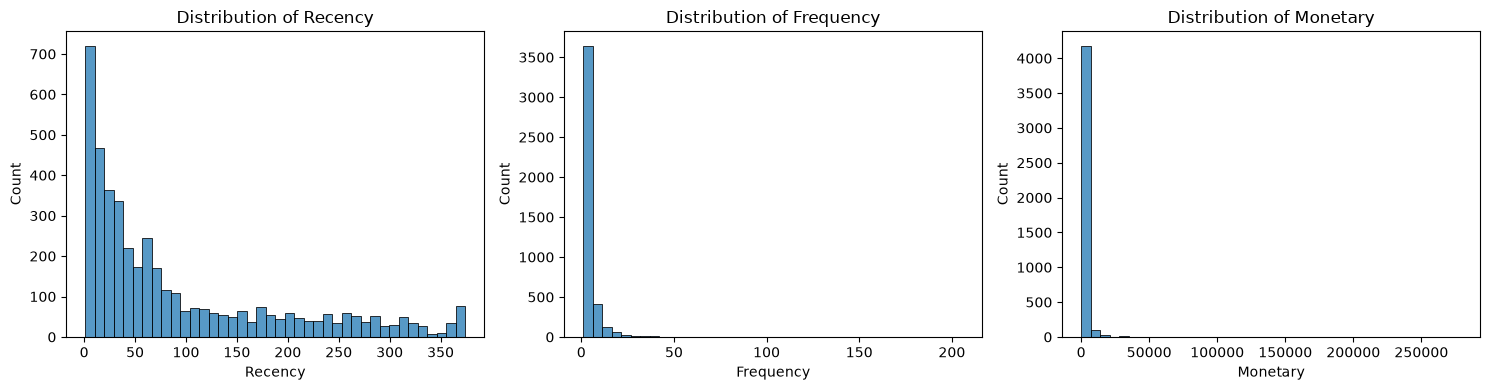

In [142]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 4))

for i, col in enumerate(
    ["Recency", "Frequency", "Monetary"], 1
):
    plt.subplot(1, 3, i)
    sns.histplot(data=rfm, x=col, bins=40)
    plt.title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

In [143]:
rfm_log = rfm[["Recency", "Frequency", "Monetary"]].copy()

rfm_log["Frequency"] = np.log1p(rfm_log["Frequency"])
rfm_log["Monetary"] = np.log1p(rfm_log["Monetary"])

In [145]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)

rfm_scaled.head()

,Recency,Frequency,Monetary
0,2.329115,-0.951280,3.726658
1,-0.905532,1.082291,1.426069
2,-0.176738,0.392837,0.550698
3,-0.735813,-0.951280,0.561880
4,2.169379,-0.951280,-0.711499


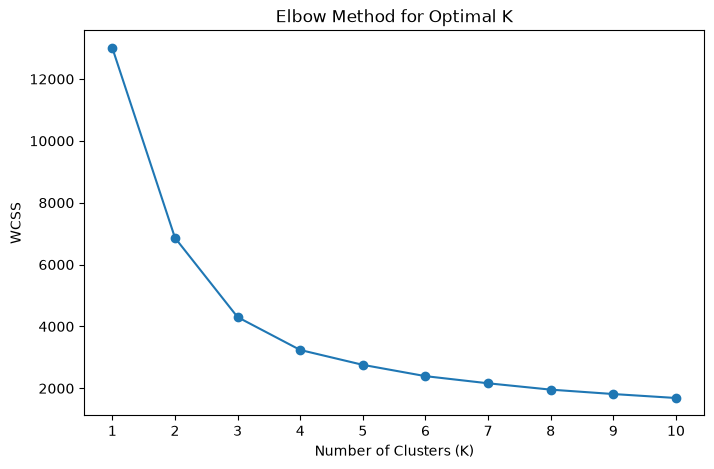

In [146]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method for Optimal K")
plt.xticks(range(1, 11))
plt.show()


In [147]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = {}

for k in range(2, 5):
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        labels
    )

    silhouette_scores[k] = score

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.4066
K = 3, Silhouette Score = 0.4151
K = 4, Silhouette Score = 0.3815


In [148]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

In [149]:
rfm["Cluster"].value_counts().sort_index()

Cluster
0    2020
1    1328
2     986
Name: count, dtype: int64

In [150]:
cluster_summary = rfm.groupby("Cluster").agg(
    CustomerCount=("CustomerID", "count"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean")
).round(2)

cluster_summary

,CustomerCount,AvgRecency,AvgFrequency,AvgMonetary
Cluster,,,,
0,2020,54.59,2.03,605.89
1,1328,30.15,9.74,5373.49
2,986,255.04,1.39,406.87


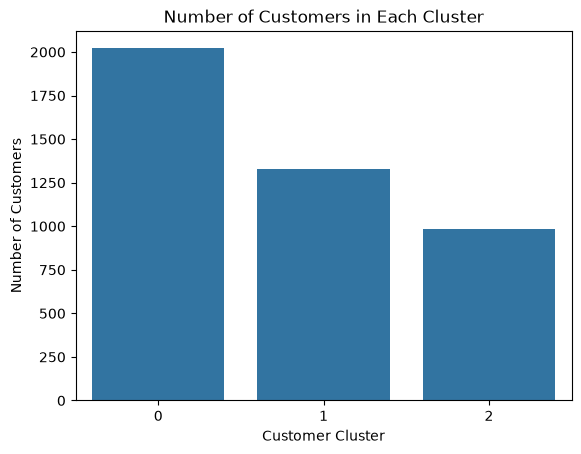

In [151]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=rfm, x="Cluster")
plt.title("Number of Customers in Each Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.show()

In [152]:
cluster_value = rfm.groupby("Cluster").agg(
    CustomerCount=("CustomerID", "count"),
    TotalMonetary=("Monetary", "sum"),
    AverageMonetary=("Monetary", "mean")
).round(2)

cluster_value

,CustomerCount,TotalMonetary,AverageMonetary
Cluster,,,
0,2020,1223900.67,605.89
1,1328,7135994.70,5373.49
2,986,401171.28,406.87


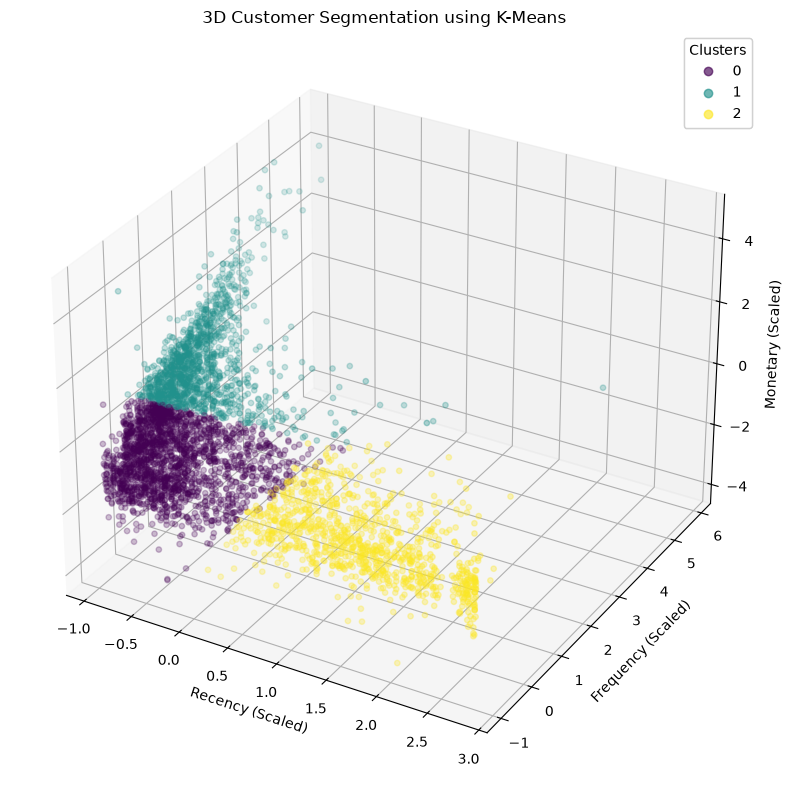

In [153]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    rfm_scaled["Recency"],
    rfm_scaled["Frequency"],
    rfm_scaled["Monetary"],
    c=rfm["Cluster"],
    cmap="viridis",
    s=15,
    alpha=0.6
)

ax.set_xlabel("Recency (Scaled)")
ax.set_ylabel("Frequency (Scaled)")
ax.set_zlabel("Monetary (Scaled)")
ax.set_title("3D Customer Segmentation using K-Means")

legend = ax.legend(
    *scatter.legend_elements(),
    title="Clusters"
)
ax.add_artist(legend)

plt.tight_layout()
plt.show()

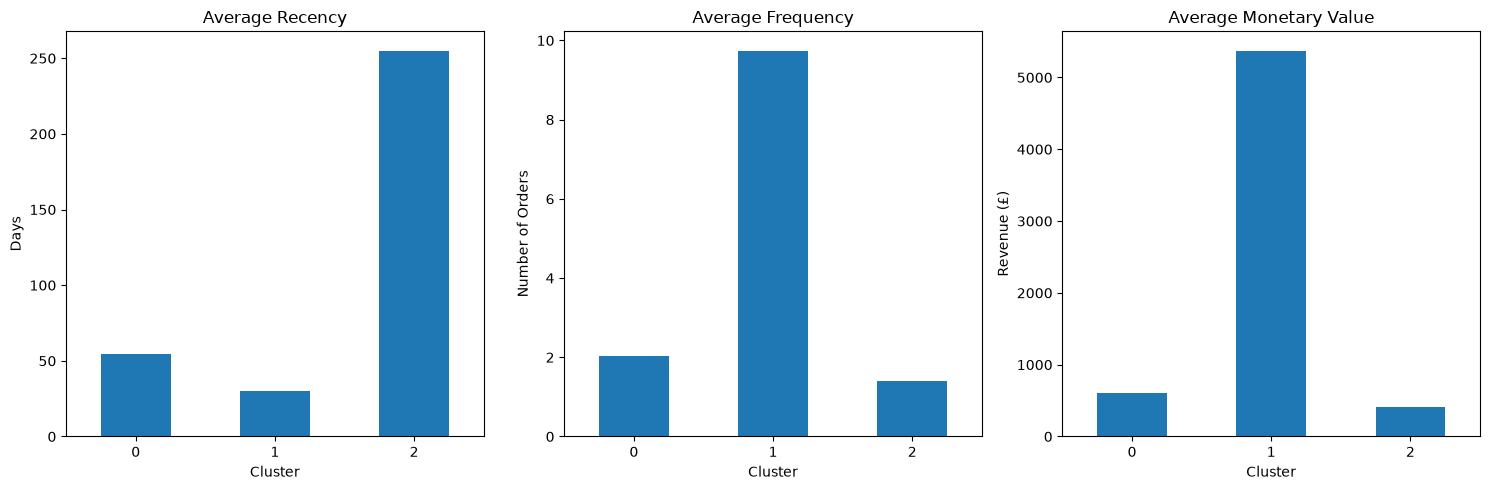

In [154]:
import matplotlib.pyplot as plt

cluster_profile = rfm.groupby("Cluster").agg(
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean")
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

cluster_profile["AvgRecency"].plot(
    kind="bar", ax=axes[0], title="Average Recency"
)
cluster_profile["AvgFrequency"].plot(
    kind="bar", ax=axes[1], title="Average Frequency"
)
cluster_profile["AvgMonetary"].plot(
    kind="bar", ax=axes[2], title="Average Monetary Value"
)

axes[0].set_ylabel("Days")
axes[1].set_ylabel("Number of Orders")
axes[2].set_ylabel("Revenue (£)")

for ax in axes:
    ax.set_xlabel("Cluster")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [155]:

from pathlib import Path

# Create the output folder inside our existing project
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Export customer-level RFM data and cluster assignments
rfm.to_csv(output_dir / "customer_segments.csv", index=False)

# Export the summary of each cluster
cluster_profile.to_csv(output_dir / "cluster_profile.csv")

print("Customer records:", len(rfm))
print("Clusters:", rfm["Cluster"].nunique())
print("Files saved to:", output_dir.resolve())


Customer records: 4334
Clusters: 3
Files saved to: D:\Customer_Segmentation_BI\data\processed
